# Floruit-only individuals: birth, works and death from a single date

In [1]:
import sys
import tempfile
from pathlib import Path

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
from style import *
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
AGE_AT_DEATH_PATH = '../../data/enriched_parquets/individual_dates_from_age_at_death.parquet'  # notebook 01
WORK_DATES_PATH = '../../data/enriched_parquets/individual_work_dates.parquet'  # notebook 02
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_dates_from_floruit.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
ANCHOR_PRECISIONS = {'day': 'year', 'month': 'year', 'year': 'year', 'decade': 'decade', 'century': 'century'}  # a millennium is too coarse
ALL = 'All'  # no recorded meta occupation: the cohort of everyone, as in 01 and 02
OCCUPATIONS = list(OCCUPATION_COLORS)
CENTURY = 100  # years
MID_DECADE = 5  # a decade counts as its middle year
MID_CENTURY = 50  # a century counts as its middle year
LAST_BIRTH_YEAR = 1920  # born later: may still be alive, no death estimated (as in 01)
WITHIN = 10  # years between the estimated and the true date
EXAMPLES = 6  # best-known individuals shown per group
RANDOM_EXAMPLES = 10  # random individuals shown at the end
FIRST_CENTURY = -800  # earliest births the test learns from, as in 01 and 02
AGE_RANGE = (10, 100)  # plausible ages at the first and the last work, as in 02
DEATH_AGE_RANGE = (0, 110)  # plausible ages at death, as in 01
MIN_COHORT = 10  # a smaller cohort takes the nearest century; a century of birth with fewer test individuals is not scored
TEST_SHARE = 0.2  # held-out share of the individuals with all four dates
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Two groups, with no birth and no death in Wikidata at any precision:
- **Floruit only**: a floruit (P1317) and no dated work at any precision.
- **Single work year only**: no floruit, and the cleaned dated works of notebook 02 (inception, else publication) all in one year.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
SINGLE_WORK_YEAR = "work_dates.first_work_date.source = 'dated works' AND work_dates.first_work_date.year = work_dates.last_work_date.year"
WORKS = """
    SELECT DISTINCT individual_work.qid
    FROM individual_work
    JOIN work ON work.entity.qid = individual_work.work_qid
    WHERE work.inception.year IS NOT NULL OR work.publication_date.year IS NOT NULL
"""
people = con.sql(f'''
    SELECT individual.entity.qid AS qid,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) AS name,
           len(individual.sitelink) AS sitelinks,
           individual.floruit_date[1].year AS floruit_year,
           individual.floruit_date[1].precision AS floruit_precision,
           len(individual.birth_date) = 0 AND len(individual.death_date) = 0 AS no_life_dates,
           list_filter(individual.birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
           list_filter(individual.death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
           individual.entity.qid IN ({WORKS}) AS has_work_date,
           coalesce({SINGLE_WORK_YEAR}, false) AS single_work_year,
           work_dates.first_work_date.year AS work_year,
           work_dates.first_work_date.precision AS work_precision
    FROM individual
    JOIN '{WORK_DATES_PATH}' AS work_dates ON work_dates.qid = individual.entity.qid
    WHERE len(individual.floruit_date) > 0 OR {SINGLE_WORK_YEAR}
''', params={'known': KNOWN_PRECISIONS}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals with a floruit or a single work year')
people.sample(5, seed=SEED)

316,947 individuals with a floruit or a single work year


qid,name,sitelinks,floruit_year,floruit_precision,no_life_dates,birth_year,death_year,has_work_date,single_work_year,work_year,work_precision
str,str,i64,i64,str,bool,i64,i64,bool,bool,i64,str
"""Q105090061""","""August M. Young""",1,null,null,false,1837,1913,true,true,1880,"""year"""
"""Q53646138""","""Isabel Graham Eaton""",1,null,null,false,1845,1920,true,true,1899,"""year"""
"""Q60036457""","""Juan de Parla""",1,null,null,true,null,null,true,true,1691,"""year"""
"""Q120367384""","""Tyrone Bravo""",0,1980,"""decade""",true,null,null,false,false,null,null
"""Q47018950""","""Johan Antony Barrau""",4,null,null,false,1873,1953,true,true,1907,"""year"""


### Individuals with all four dates, for the test
A Wikidata birth and death precise to the year or the decade and a work period from notebook 02 (first and last work in different years), with the Wikidata floruit when there is one and one of their dated works drawn at random (a work dated by its inception, else its publication, a decade counting as its middle year, between the first and the last work).

In [3]:
truth = con.sql(f'''
    WITH truth AS (
        SELECT individual.entity.qid AS qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) AS name,
               individual.floruit_date[1].year AS floruit_year,
               individual.floruit_date[1].precision AS floruit_precision,
               list_filter(individual.birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(individual.death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
               work_dates.first_work_date.year AS first_year,
               work_dates.last_work_date.year AS last_year
        FROM individual
        JOIN '{WORK_DATES_PATH}' AS work_dates ON work_dates.qid = individual.entity.qid
        WHERE work_dates.first_work_date.source = 'dated works' AND work_dates.first_work_date.year < work_dates.last_work_date.year
    ),
    dated AS (
        SELECT individual_work.qid, individual_work.work_qid,
               CASE WHEN list_contains($known, work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        JOIN truth ON truth.qid = individual_work.qid
        WHERE list_contains($known, work.inception.precision) OR list_contains($known, work.publication_date.precision)
    ),
    drawn AS (
        SELECT dated.qid, dated.date.year + CASE WHEN dated.date.precision = 'decade' THEN $mid_decade ELSE 0 END AS work_year
        FROM dated
        JOIN truth ON truth.qid = dated.qid
        WHERE dated.date.year + CASE WHEN dated.date.precision = 'decade' THEN $mid_decade ELSE 0 END BETWEEN truth.first_year AND truth.last_year
        QUALIFY row_number() OVER (PARTITION BY dated.qid ORDER BY hash(dated.work_qid || $seed)) = 1
    )
    SELECT truth.*, drawn.work_year
    FROM truth
    JOIN drawn ON drawn.qid = truth.qid
    WHERE truth.birth_year IS NOT NULL AND truth.death_year IS NOT NULL
''', params={'known': KNOWN_PRECISIONS, 'mid_decade': MID_DECADE, 'seed': str(SEED)}).pl()
assert truth['qid'].is_unique().all()
print(f'{truth.height:,} individuals with a birth, a death and a work period')
truth.sample(5, seed=SEED)

120,123 individuals with a birth, a death and a work period


qid,name,floruit_year,floruit_precision,birth_year,death_year,first_year,last_year,work_year
str,str,i64,str,i64,i64,i64,i64,i64
"""Q2253244""","""Francesco Cairo""",null,null,1607,1665,1630,1655,1645
"""Q2330447""","""John Axel Nannfeldt""",null,null,1904,1985,1931,1984,1938
"""Q1934264""","""Milan Machovec""",null,null,1925,2003,1953,1968,1953
"""Q2852968""","""Anthony Spinelli""",null,null,1927,2000,1964,1984,1981
"""Q4535114""","""Aleksandr Yurovsky""",null,null,1921,2003,1961,1985,1978


### Individuals with no birth and no death

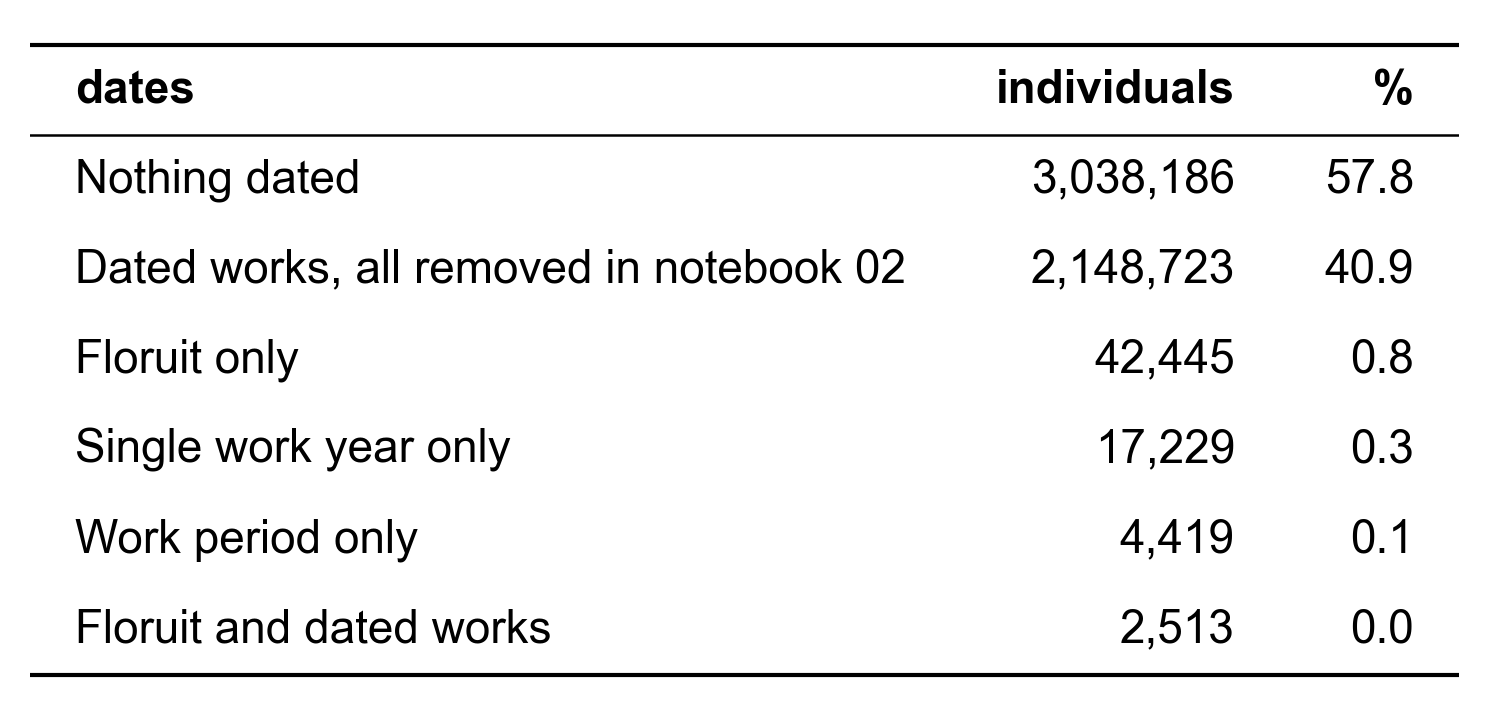

In [4]:
no_life = con.sql(f'''
    SELECT CASE
               WHEN len(individual.floruit_date) > 0 AND NOT individual.entity.qid IN ({WORKS}) THEN 'Floruit only'
               WHEN len(individual.floruit_date) > 0 THEN 'Floruit and dated works'
               WHEN {SINGLE_WORK_YEAR} THEN 'Single work year only'
               WHEN work_dates.first_work_date.source = 'dated works' THEN 'Work period only'
               WHEN individual.entity.qid IN ({WORKS}) THEN 'Dated works, all removed in notebook 02'
               ELSE 'Nothing dated'
           END AS dates,
           count(*) AS individuals
    FROM individual
    JOIN '{WORK_DATES_PATH}' AS work_dates ON work_dates.qid = individual.entity.qid
    WHERE len(individual.birth_date) = 0 AND len(individual.death_date) = 0
    GROUP BY ALL
    ORDER BY individuals DESC
''').pl()
show_table(no_life.with_columns((100 * pl.col('individuals') / pl.col('individuals').sum()).alias('%')), decimals=1)

In [5]:
floruit_only = people.filter(pl.col('no_life_dates') & pl.col('floruit_year').is_not_null() & ~pl.col('has_work_date'))
single_work = people.filter(pl.col('no_life_dates') & pl.col('floruit_year').is_null() & pl.col('single_work_year'))
assert floruit_only.height == no_life.filter(pl.col('dates') == 'Floruit only')['individuals'][0]
assert single_work.height == no_life.filter(pl.col('dates') == 'Single work year only')['individuals'][0]
print(f'{floruit_only.height:,} floruit only, {single_work.height:,} single work year only')

42,445 floruit only, 17,229 single work year only


### Precision of the floruits
In Wikidata a century-precision year names its century by its last year: 1500 is the 15th century (1401–1500) and 1501 the 16th, which the descriptions confirm ("15th-century painter" for 1500). A year ending in 50 marks the middle of the century, the only "mid-century" information the floruit value carries. The qualifier *refine date* (P4241: first half, middle of, end of…) is on about 400 of the 15,000 century floruits of Wikidata (QLever, 28 October 2026) and is not in the database.

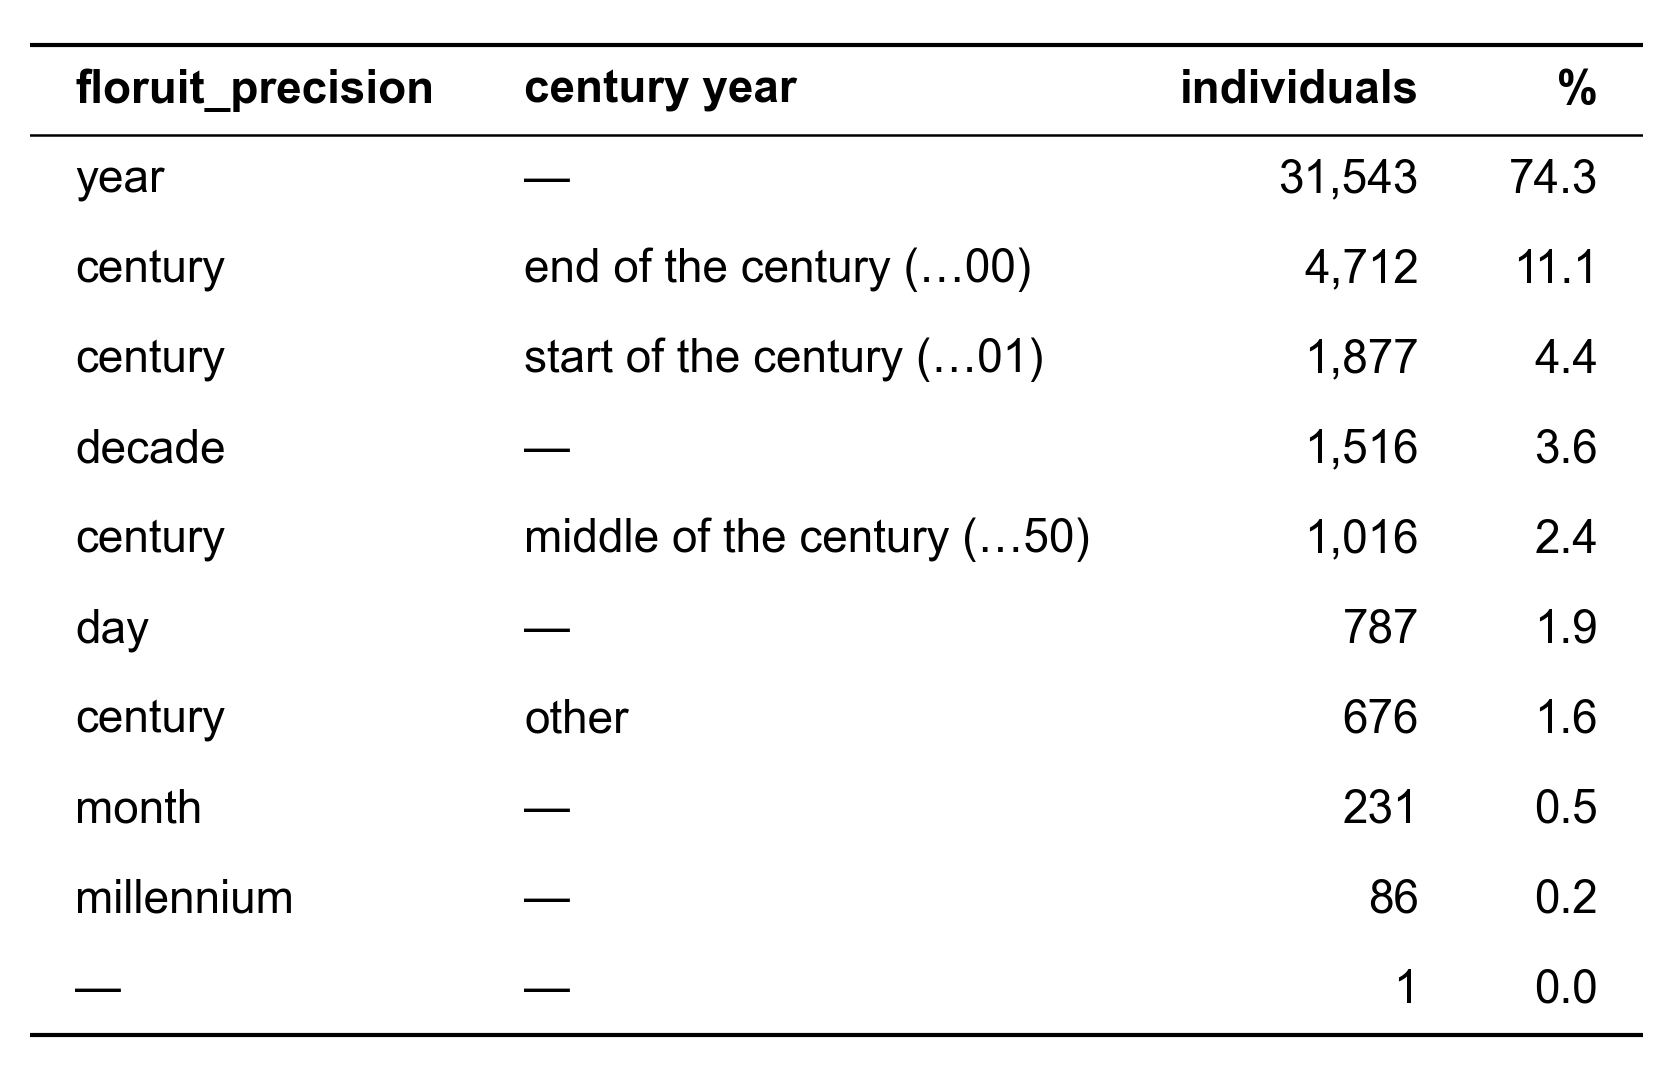

In [6]:
CENTURY_YEAR = (
    pl.when(pl.col('floruit_precision').fill_null('') != 'century').then(pl.lit(None))
    .when(pl.col('floruit_year').abs() % CENTURY == MID_CENTURY).then(pl.lit('middle of the century (…50)'))
    .when(pl.col('floruit_year').abs() % CENTURY == 0).then(pl.lit('end of the century (…00)'))
    .when(pl.col('floruit_year').abs() % CENTURY == 1).then(pl.lit('start of the century (…01)'))
    .otherwise(pl.lit('other'))
)
precision = floruit_only.group_by('floruit_precision', CENTURY_YEAR.alias('century year')).len('individuals').sort('individuals', descending=True)
show_table(precision.with_columns((100 * pl.col('individuals') / floruit_only.height).alias('%')), decimals=1)

### The year each date stands for
Day, month and year precisions keep their year; a decade counts as its middle year (1840s → 1845); a century as its middle (1500 or 1401 → 1450, 1550 → 1550, 500 BC → 450 BC). Millennium floruits are left out. A single work year keeps the year of notebook 02 (a decade there already counts as its middle year).

In [7]:
def century_middle(year):
    """The middle of the Wikidata century a year names: 1401–1500 → 1450, 1501–1600 → 1550; the same backwards before the common era."""
    end = (year.abs() + CENTURY - 1) // CENTURY * CENTURY
    return year.sign() * (end - MID_CENTURY)


def anchored(frame, year, precision, source):
    return frame.filter(precision.is_in(list(ANCHOR_PRECISIONS))).with_columns(
        pl.when(precision == 'century').then(century_middle(year))
        .when(precision == 'decade').then(year + MID_DECADE)
        .otherwise(year).cast(pl.Int64).alias('anchor_year'),
        precision.replace_strict(ANCHOR_PRECISIONS).alias('anchor_precision'),
        pl.lit(source).alias('anchor'),
    )


targets = pl.concat([
    anchored(floruit_only, pl.col('floruit_year'), pl.col('floruit_precision'), 'floruit'),
    single_work.with_columns(pl.col('work_year').alias('anchor_year'), pl.col('work_precision').alias('anchor_precision'), pl.lit('single work year').alias('anchor')),
], how='diagonal')
print(f'{floruit_only.height - targets.filter(pl.col("anchor") == "floruit").height:,} millennium floruits (or with no precision) left out')
assert century_middle(pl.Series([1500, 1401, 1501, 1550, 1600, -500, -401, -450])).to_list() == [1450, 1450, 1550, 1550, 1550, -450, -450, -450]
targets.group_by('anchor', 'anchor_precision').len('individuals').sort('anchor', 'individuals')

87 millennium floruits (or with no precision) left out


anchor,anchor_precision,individuals
str,str,u32
"""floruit""","""decade""",1516
"""floruit""","""century""",8281
"""floruit""","""year""",32561
"""single work year""","""decade""",269
"""single work year""","""year""",16960


### Main meta occupation
As in notebooks 01 and 02: the meta occupation most of the individual's occupations fall in, the first listed on a tie; All when none.

In [8]:
def main_occupation(frame):
    con.register('candidates', frame.select('qid').to_arrow())
    occupations = con.sql('''
        WITH held AS (
            SELECT individual.entity.qid AS qid, unnest(individual.occupation).entity.qid AS occupation_qid, generate_subscripts(individual.occupation, 1) AS position
            FROM individual
            JOIN candidates ON candidates.qid = individual.entity.qid
        ),
        counted AS (
            SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
            FROM held
            JOIN occupation ON occupation.entity.qid = held.occupation_qid
            WHERE list_contains($occupations, occupation.meta_occupation)
            GROUP BY ALL
        )
        SELECT qid, occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ''', params={'occupations': OCCUPATIONS}).pl()
    return frame.join(occupations, on='qid', how='left').with_columns(pl.col('occupation').fill_null(ALL))


people = main_occupation(people)
truth = main_occupation(truth)
targets = targets.drop('occupation', strict=False).join(people.select('qid', 'occupation'), on='qid')
targets.group_by('anchor', 'occupation').len('individuals').sort('anchor', 'individuals', descending=[False, True])

anchor,occupation,individuals
str,str,u32
"""floruit""","""Culture""",22633
"""floruit""","""All""",10862
"""floruit""","""Discovery/Science""",4451
"""floruit""","""Leadership""",4108
"""floruit""","""Sports/Games""",304
"""single work year""","""Culture""",7928
"""single work year""","""All""",6603
"""single work year""","""Discovery/Science""",2496
"""single work year""","""Leadership""",185


## Cohort ages from the parquets
The cohorts notebooks 01 and 02 estimated from, read back from their parquets: the mean age at death (01) and the median ages at the first and the last work (02) for each meta occupation and century of birth, All being everyone.

In [9]:
def parquet_cohorts(path, *columns):
    """The distinct cohorts behind the estimated dates of `columns` in a parquet."""
    union = ' UNION '.join(f'''
        SELECT DISTINCT coalesce({column}.cohort.occupation, $all) AS occupation, {column}.cohort.century AS cohort_century,
               {column}.cohort.individuals AS cohort_individuals, round({column}.cohort.age, 6) AS age
        FROM '{path}'
        WHERE {column}.source = 'estimated'
    ''' for column in columns)
    cohorts = con.sql(union, params={'all': ALL}).pl().sort('occupation', 'cohort_century')
    assert cohorts.select('occupation', 'cohort_century').is_unique().all()
    return cohorts


death_cohorts = parquet_cohorts(AGE_AT_DEATH_PATH, 'birth_date', 'death_date')
work_cohorts = parquet_cohorts(WORK_DATES_PATH, 'first_work_date').rename({'age': 'first_age'}).join(
    parquet_cohorts(WORK_DATES_PATH, 'last_work_date').select('occupation', 'cohort_century', pl.col('age').alias('last_age')),
    on=['occupation', 'cohort_century'],
)
assert work_cohorts.height == parquet_cohorts(WORK_DATES_PATH, 'last_work_date').height
everyone = work_cohorts.filter(pl.col('occupation') == ALL)
MID_WORK_AGE = ((everyone['first_age'] + everyone['last_age']) / 2 * everyone['cohort_individuals']).sum() / everyone['cohort_individuals'].sum()
print(f'{death_cohorts.height} age-at-death cohorts, {work_cohorts.height} work cohorts; age at the middle of the work period, everyone: {MID_WORK_AGE:.1f}')
work_cohorts.filter(pl.col('occupation') == ALL).with_columns((pl.col('last_age') - pl.col('first_age')).alias('work_period'))

117 age-at-death cohorts, 41 work cohorts; age at the middle of the work period, everyone: 48.2


occupation,cohort_century,cohort_individuals,first_age,last_age,work_period
str,i64,i64,f64,f64,f64
"""All""",700,14,43.0,60.5,17.5
"""All""",900,11,40.0,49.0,9.0
"""All""",1000,18,41.5,58.5,17.0
"""All""",1100,55,43.0,60.0,17.0
"""All""",1200,91,41.0,59.0,18.0
"""All""",1300,177,33.0,55.0,22.0
"""All""",1400,775,30.0,52.0,22.0
"""All""",1500,1356,30.0,53.0,23.0
"""All""",1600,2604,29.5,53.0,23.5


## Model
The floruit (or the single work year) is the middle of the work period, or the time of the major work the individual is remembered for:
1. The century of birth is first guessed as the date minus the age at the middle of the work period of everyone; the individual takes the work cohort of their occupation born in that century (the nearest century with a cohort), then, once, the cohort of the century of the birth it gives (steps 2–3).
2. First work = date − half the cohort's work period; last work = date + half of it.
3. Birth = first work − the cohort's age at first work.
4. Death = birth + the mean age at death of the occupation born in that century, no earlier than the last work; none for births after 1920.

For 1745, a work period of 20 years, a first work at 20 and death at 70: works 1735–1755, birth 1715, death 1785.

In [10]:
def nearest(frame, cohorts, century, prefix):
    """The cohort of the individual's occupation whose century of birth is nearest to `century`, the later one on a tie."""
    matched = (
        frame.select('qid', 'occupation', century.cast(pl.Int64).alias('century')).join(cohorts, on='occupation')
        .sort('qid', (pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, False, True])
        .group_by('qid', maintain_order=True).first()
    )
    assert matched.height == frame.height
    return frame.join(matched.drop('occupation').rename(lambda c: c if c == 'qid' else f'{prefix}_{c}'), on='qid')


def work_period(frame, century, works):
    """Works = date ∓ half the work period of the cohort born in `century`, birth = first work − its age at first work."""
    frame = nearest(frame, works, century, 'work')
    frame = frame.with_columns(((pl.col('work_last_age') - pl.col('work_first_age')) / 2).round().cast(pl.Int64).alias('half_period'))
    return frame.with_columns(
        (pl.col('anchor_year') - pl.col('half_period')).alias('first_work_year'),
        (pl.col('anchor_year') + pl.col('half_period')).alias('last_work_year'),
        (pl.col('anchor_year') - pl.col('half_period') - pl.col('work_first_age').round().cast(pl.Int64)).alias('estimated_birth_year'),
    )


def estimate(frame, works=work_cohorts, deaths=death_cohorts, mid_work_age=MID_WORK_AGE):
    """The work period from the guessed century of birth, again from the century of the birth it gives; death = birth + the age at death."""
    guessed = work_period(frame, (pl.col('anchor_year') - mid_work_age) // CENTURY * CENTURY, works)
    frame = frame.join(guessed.select('qid', (pl.col('estimated_birth_year') // CENTURY * CENTURY).alias('guessed_century')), on='qid')
    frame = work_period(frame, pl.col('guessed_century'), works)
    frame = nearest(frame, deaths, pl.col('estimated_birth_year') // CENTURY * CENTURY, 'death')
    from_age = pl.col('estimated_birth_year') + pl.col('death_age').round().cast(pl.Int64)
    return frame.with_columns(
        pl.when(pl.col('estimated_birth_year') <= LAST_BIRTH_YEAR).then(pl.max_horizontal(from_age, 'last_work_year')).alias('estimated_death_year'),
        (from_age < pl.col('last_work_year')).alias('death_raised'),
    )


worked = estimate(pl.DataFrame({'qid': ['example'], 'occupation': [ALL], 'anchor_year': [1745]}))
worked.select('anchor_year', 'work_cohort_century', 'work_first_age', 'work_last_age', 'estimated_birth_year', 'first_work_year', 'last_work_year', 'estimated_death_year')

anchor_year,work_cohort_century,work_first_age,work_last_age,estimated_birth_year,first_work_year,last_work_year,estimated_death_year
i64,i64,f64,f64,i64,i64,i64,i64
1745,1700,32.0,54.0,1702,1734,1756,1767


## Estimation

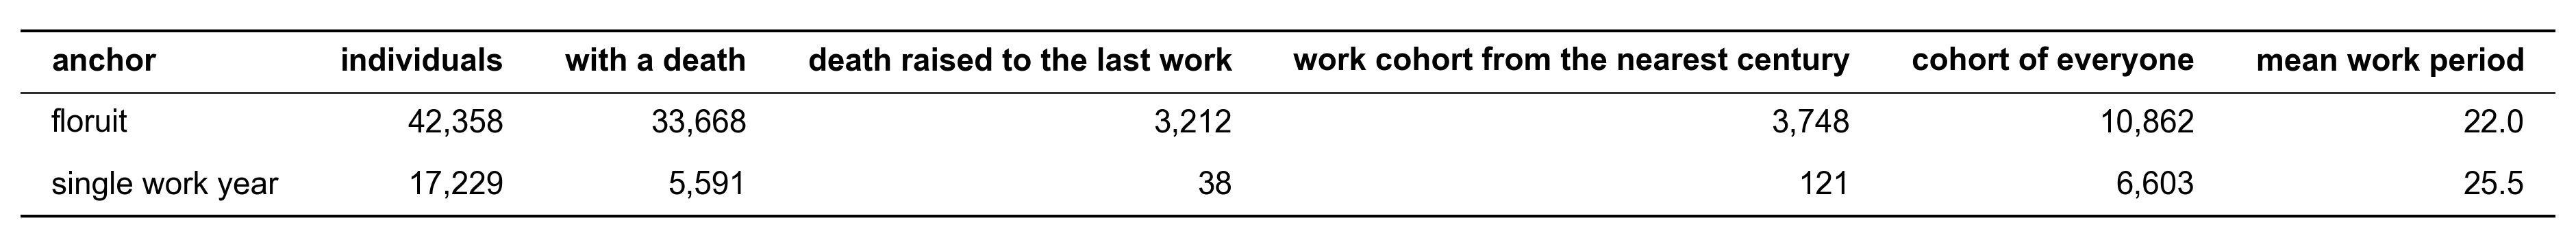

In [11]:
estimated = estimate(targets)
assert estimated.height == targets.height and estimated['estimated_birth_year'].null_count() == 0
summary = estimated.group_by('anchor').agg(
    pl.len().alias('individuals'),
    pl.col('estimated_death_year').is_not_null().sum().alias('with a death'),
    pl.col('death_raised').sum().alias('death raised to the last work'),
    (pl.col('work_cohort_century') != pl.col('work_century')).sum().alias('work cohort from the nearest century'),
    (pl.col('occupation') == ALL).sum().alias('cohort of everyone'),
    pl.col('half_period').mul(2).mean().round(1).alias('mean work period'),
).sort('anchor')
show_table(summary, decimals=1)

### Estimated dates of the best-known individuals of each group, with the cohort used

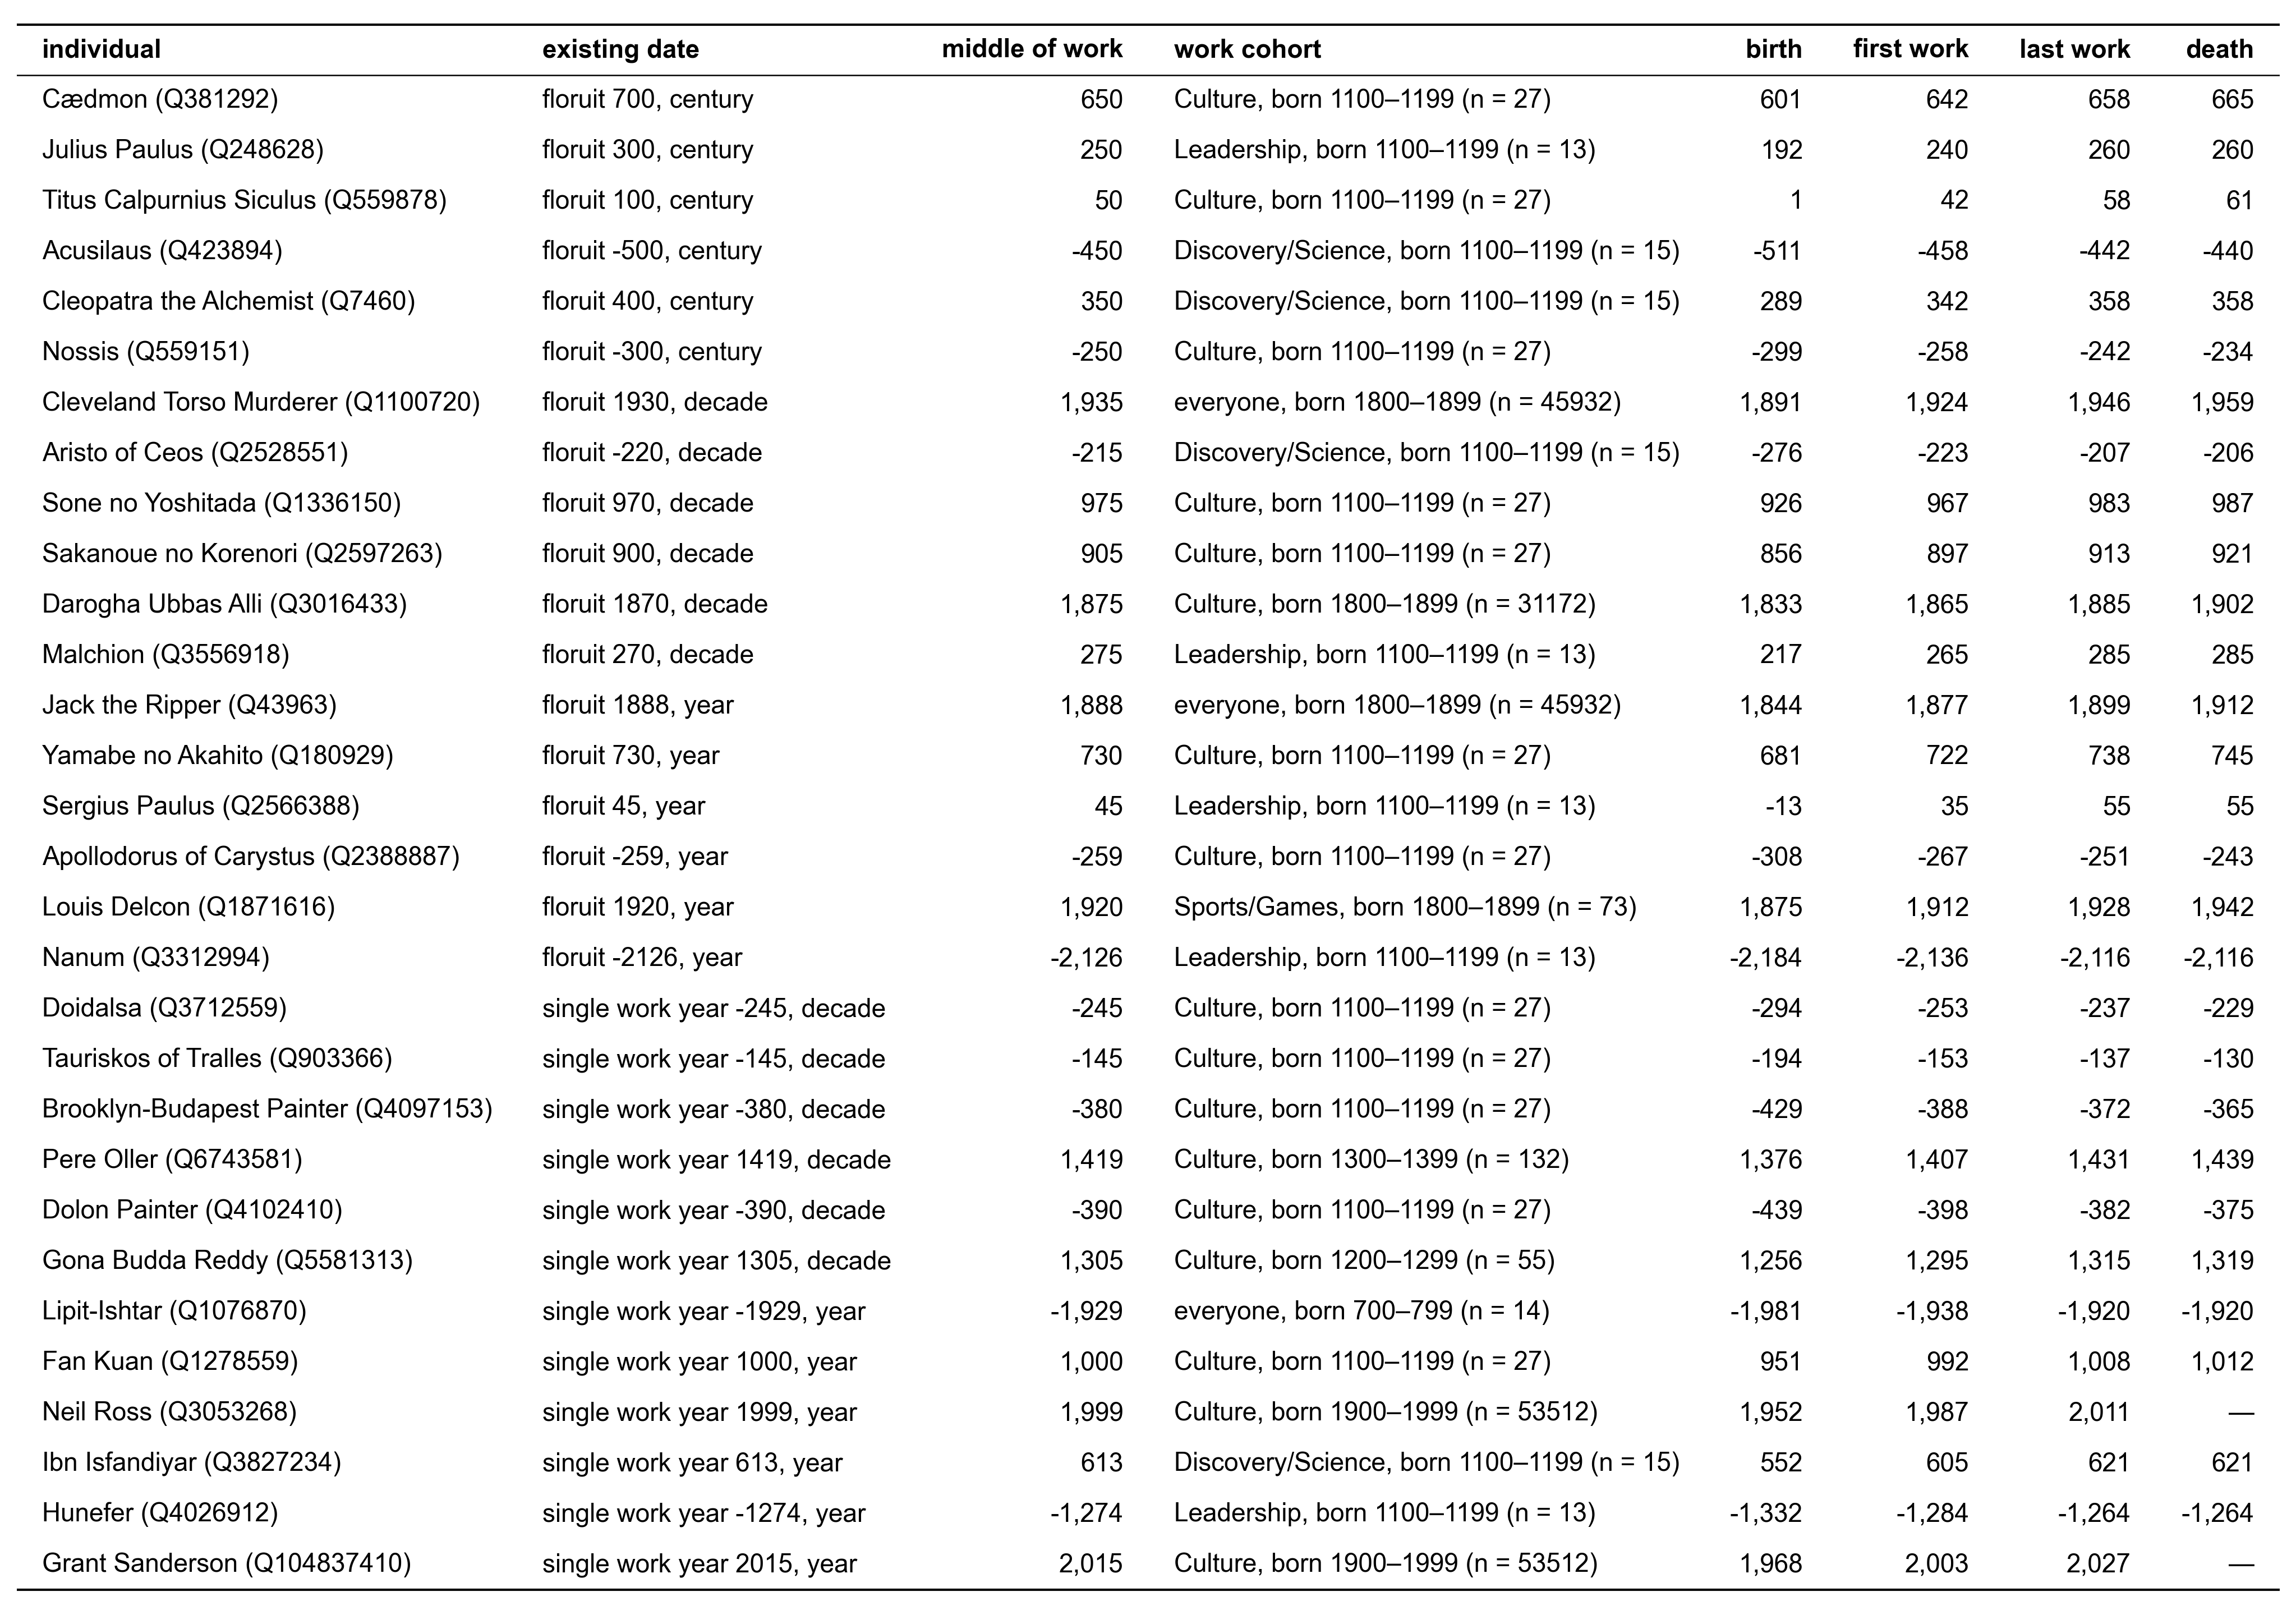

In [12]:
def cohort_label(prefix):
    group = pl.when(pl.col('occupation') == ALL).then(pl.lit('everyone')).otherwise(pl.col('occupation'))
    return pl.format('{}, born {}–{} (n = {})', group, f'{prefix}_cohort_century', pl.col(f'{prefix}_cohort_century') + CENTURY - 1, f'{prefix}_cohort_individuals')


def dates_table(frame):
    """The existing date of each individual and the four dates estimated from it."""
    return frame.select(
        pl.format('{} ({})', 'name', 'qid').alias('individual'),
        pl.format('{} {}, {}', 'anchor', pl.coalesce(pl.col('floruit_year'), pl.col('work_year')), 'anchor_precision').alias('existing date'),
        pl.col('anchor_year').alias('middle of work'),
        cohort_label('work').alias('work cohort'),
        pl.col('estimated_birth_year').alias('birth'),
        pl.col('first_work_year').alias('first work'),
        pl.col('last_work_year').alias('last work'),
        pl.col('estimated_death_year').alias('death'),
    )


examples = (
    estimated.join(people.select('qid', 'name', 'sitelinks'), on='qid')
    .sort('sitelinks', 'qid', descending=[True, False])
    .group_by('anchor', 'anchor_precision', maintain_order=True).head(EXAMPLES)
    .sort('anchor', 'anchor_precision', 'sitelinks', descending=[False, False, True])
)
show_table(dates_table(examples))

## Save
One row per estimated individual with `IndividualEnriched.birth_date`, `death_date`, `first_work_date` and `last_work_date`, `source = 'estimated'` with the cohort used; the precision is that of the floruit or the work year (day and month → year); `field_provenance` gives the rule.

In [13]:
DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.floruit_date', 'IndividualEnriched.first_work_date', 'IndividualEnriched.last_work_date', 'Individual.birth_date', 'Individual.death_date', 'Occupation.meta_occupation']


def group_text():
    return pl.when(pl.col('occupation') == ALL).then(pl.lit('individuals')).otherwise(pl.col('occupation') + ' individuals')


def born_text(prefix):
    return pl.format('born in {}–{}', f'{prefix}_cohort_century', pl.col(f'{prefix}_cohort_century') + CENTURY - 1)


def anchor_text():
    floruit = pl.when(pl.col('anchor_precision') == 'century').then(pl.format('the floruit {} (century precision, the middle of its century)', 'floruit_year'))
    floruit = floruit.when(pl.col('anchor_precision') == 'decade').then(pl.format('the floruit {} (decade precision, its middle year)', 'floruit_year'))
    floruit = floruit.otherwise(pl.format('the floruit {}', 'floruit_year'))
    return pl.when(pl.col('anchor') == 'floruit').then(floruit).otherwise(pl.format('the single year of the dated works {}', 'work_year'))


def work_rule(end):
    sign = '−' if end == 'first' else '+'
    return pl.format(f'Estimated from {{}}, taken as the middle of the work period: {{}} {sign} {{}} years, half the work period (median ages {{}} to {{}} at the first and the last work) of the {{}} {{}} {{}} (notebook 02).',
                     anchor_text(), 'anchor_year', 'half_period', pl.col('work_first_age').round(1), pl.col('work_last_age').round(1), 'work_cohort_individuals', group_text(), born_text('work'))


def birth_rule():
    return pl.format('Estimated from {}: the estimated first work {} − {} years, the median age at first work of the {} {} {} (notebook 02).',
                     anchor_text(), 'first_work_year', pl.col('work_first_age').round(1), 'work_cohort_individuals', group_text(), born_text('work'))


def death_rule():
    raised = pl.when(pl.col('death_raised')).then(pl.lit(', raised to the estimated last work')).otherwise(pl.lit(''))
    return pl.format('Estimated from {}: the estimated birth {} + {} years, the mean age at death of the {} {} {} (notebook 01){}.',
                     anchor_text(), 'estimated_birth_year', pl.col('death_age').round(1), 'death_cohort_individuals', group_text(), born_text('death'), raised)


def cohort(prefix, age):
    return pl.struct(
        pl.when(pl.col('occupation') != ALL).then('occupation').alias('occupation'),
        pl.col(f'{prefix}_cohort_century').alias('century'),
        pl.col(f'{prefix}_cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col(age).cast(pl.Float64).alias('age'),
    )


dates = estimated.select(
    'qid', 'anchor_precision',
    pl.col('estimated_birth_year').alias('birth_year'), birth_rule().alias('birth_rule'), cohort('work', 'work_first_age').alias('birth_cohort'),
    pl.col('estimated_death_year').alias('death_year'), death_rule().alias('death_rule'), cohort('death', 'death_age').alias('death_cohort'),
    pl.col('first_work_year').alias('first_work_year'), work_rule('first').alias('first_work_rule'), cohort('work', 'work_first_age').alias('first_work_cohort'),
    pl.col('last_work_year').alias('last_work_year'), work_rule('last').alias('last_work_rule'), cohort('work', 'work_last_age').alias('last_work_cohort'),
)
con.register('dates', dates.to_arrow())


def estimated_date(name):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': dates.{name}_rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CASE WHEN dates.{name}_year IS NOT NULL THEN CAST({{'iso': NULL, 'year': dates.{name}_year, 'precision': dates.anchor_precision,
        'field_provenance': MAP {{'year': {provenance}, 'precision': {provenance}}}, 'source': 'estimated', 'cohort': dates.{name}_cohort}} AS {DATE_TYPE}) END AS {name}_date"""


FLORUIT_DATES = f"SELECT dates.qid, {', '.join(estimated_date(name) for name in ['birth', 'death', 'first_work', 'last_work'])} FROM dates"
con.sql(f'SELECT * FROM ({FLORUIT_DATES}) LIMIT 4', params={'inputs': INPUTS}).pl()

qid,birth_date,death_date,first_work_date,last_work_date
str,struct[6],struct[6],struct[6],struct[6]
"""Q100139581""","{null,1509,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated first work 1538 − 29.0 years, the median age at first work of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated first work 1538 − 29.0 years, the median age at first work of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1500,1153,29.0}}","{null,1569,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated birth 1509 + 60.4 years, the mean age at death of the 9794 Culture individuals born in 1500–1599 (notebook 01)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated birth 1509 + 60.4 years, the mean age at death of the 9794 Culture individuals born in 1500–1599 (notebook 01)."",null,null}}],""estimated"",{""Culture"",1500,9794,60.411987}}","{null,1538,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 − 12 years, half the work period (median ages 29.0 to 52.0 at the first and the last work) of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 − 12 years, half the work period (median ages 29.0 to 52.0 at the first and the last work) of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1500,1153,29.0}}","{null,1562,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 + 12 years, half the work period (median ages 29.0 to 52.0 at the first and the last work) of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 + 12 years, half the work period (median ages 29.0 to 52.0 at the first and the last work) of the 1153 Culture individuals born in 1500–1599 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1500,1153,52.0}}"
"""Q100144584""","{null,1450,""year"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1490: the estimated first work 1479 − 29.0 years, the median age at first work of the 654 Culture individuals born in 1400–1499 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1490: the estimated first wor

In [14]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    con.execute(f"COPY ({FLORUIT_DATES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = con.sql(f"SELECT count(*) AS individuals, count(birth_date) AS births, count(death_date) AS deaths, count(first_work_date) AS first_works, count(last_work_date) AS last_works FROM '{OUTPUT_PATH}'").pl()
    assert saved['individuals'][0] == saved['births'][0] == saved['first_works'][0] == estimated.height
    display(saved)

individuals,births,deaths,first_works,last_works
i64,i64,i64,i64,i64
59587,59587,39259,59587,59587


## Test on a held-out 20%
The individuals with all four dates, born from 800 BC to 1920, with their first and last works between the ages of 10 and 100 and their death between 0 and 110, split 80/20. On the 80%, the cohorts are learnt as in 01 and 02: for each meta occupation and century of birth (the century alone for everyone), the median ages at the first and the last work and the mean age at death, a cohort under 10 individuals taking the nearest century. On the 20%, the four dates are estimated from one date alone: one of their dated works drawn at random, or the Wikidata floruit for those with one. Each score is computed in every true century of birth with at least 10 test individuals, then averaged over those centuries (each century weighs the same).

In [15]:
lives = truth.with_columns(
    (pl.col('first_year') - pl.col('birth_year')).alias('age_at_first_work'),
    (pl.col('last_year') - pl.col('birth_year')).alias('age_at_last_work'),
    (pl.col('death_year') - pl.col('birth_year')).alias('age_at_death'),
    (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
)
log = [{'step': 'all four dates', 'individuals': lives.height}]
for step, keep in {
    f'born {FIRST_CENTURY} to {LAST_BIRTH_YEAR}': pl.col('birth_year').is_between(FIRST_CENTURY, LAST_BIRTH_YEAR),
    f'works between the ages of {AGE_RANGE[0]} and {AGE_RANGE[1]}': pl.col('age_at_first_work').is_between(*AGE_RANGE) & pl.col('age_at_last_work').is_between(*AGE_RANGE),
    f'death between the ages of {DEATH_AGE_RANGE[0]} and {DEATH_AGE_RANGE[1]}': pl.col('age_at_death').is_between(*DEATH_AGE_RANGE) & (pl.col('death_year') >= pl.col('last_year')),
}.items():
    lives = lives.filter(keep)
    log.append({'step': step, 'individuals': lives.height})
test = lives.sort('qid').sample(fraction=TEST_SHARE, shuffle=True, seed=SEED)
train = lives.join(test, on='qid', how='anti')
assert train.height + test.height == lives.height
print(f'train: {train.height:,}, test: {test.height:,}')
pl.DataFrame(log)

train: 62,124, test: 15,530


step,individuals
str,i64
"""all four dates""",120123
"""born -800 to 1920""",78788
"""works between the ages of 10 a…",77669
"""death between the ages of 0 an…",77654


In [16]:
def learnt_cohorts(lives, *stats):
    """The stats of each meta occupation and century of birth, and of the century alone for everyone, in cohorts of at least MIN_COHORT."""
    by_occupation = lives.filter(pl.col('occupation') != ALL).group_by('occupation', 'century').agg(pl.len().alias('cohort_individuals'), *stats)
    everyone = lives.group_by('century').agg(pl.len().alias('cohort_individuals'), *stats).with_columns(pl.lit(ALL).alias('occupation'))
    return pl.concat([by_occupation, everyone], how='diagonal').filter(pl.col('cohort_individuals') >= MIN_COHORT).rename({'century': 'cohort_century'})


train_works = learnt_cohorts(train, pl.col('age_at_first_work').median().alias('first_age'), pl.col('age_at_last_work').median().alias('last_age'))
train_deaths = learnt_cohorts(train, pl.col('age_at_death').mean().alias('age'))
train_everyone = train_works.filter(pl.col('occupation') == ALL)
train_mid_age = ((train_everyone['first_age'] + train_everyone['last_age']) / 2 * train_everyone['cohort_individuals']).sum() / train_everyone['cohort_individuals'].sum()
print(f'{train_works.height} work cohorts, {train_deaths.height} age-at-death cohorts; age at the middle of the work period, everyone: {train_mid_age:.1f}')

40 work cohorts, 40 age-at-death cohorts; age at the middle of the work period, everyone: 44.6


In [17]:
MEASURES = {'birth': ('estimated_birth_year', 'birth_year'), 'first work': ('first_work_year', 'first_year'),
            'last work': ('last_work_year', 'last_year'), 'death': ('estimated_death_year', 'death_year')}
INPUTS = {
    'a random dated work': test.with_columns(pl.col('work_year').alias('anchor_year')),
    'the Wikidata floruit': anchored(test.filter(pl.col('floruit_year').is_not_null()), pl.col('floruit_year'), pl.col('floruit_precision'), 'floruit'),
}


def century_scores(frame, input_name):
    """% within WITHIN years and mean absolute error of each date, per true century of birth, averaged over the centuries."""
    errors = frame.select('century', *[(pl.col(estimated) - pl.col(true)).abs().alias(measure) for measure, (estimated, true) in MEASURES.items()])
    per_century = errors.group_by('century').agg(
        pl.len().alias('individuals'),
        *[(100 * (pl.col(measure) <= WITHIN).mean()).alias(f'{measure} within') for measure in MEASURES],
        *[pl.col(measure).mean().alias(f'{measure} error') for measure in MEASURES],
    ).filter(pl.col('individuals') >= MIN_COHORT)
    row = {'estimated from': input_name, 'test individuals': per_century['individuals'].sum(), 'centuries': per_century.height}
    for measure in MEASURES:
        row[f'{measure.capitalize()} within {WITHIN} years [mean absolute error]'] = f"{per_century[f'{measure} within'].mean():.1f}% [{per_century[f'{measure} error'].mean():.1f}]"
    return row


held_out = {name: estimate(frame, train_works, train_deaths, train_mid_age) for name, frame in INPUTS.items()}
assert all(held_out[name].height == INPUTS[name].height for name in INPUTS)
held_out_scores = pl.DataFrame([century_scores(frame, name) for name, frame in held_out.items()])

### % of the held-out 20% estimated within 10 years [mean absolute error, in years], averaged over centuries of birth

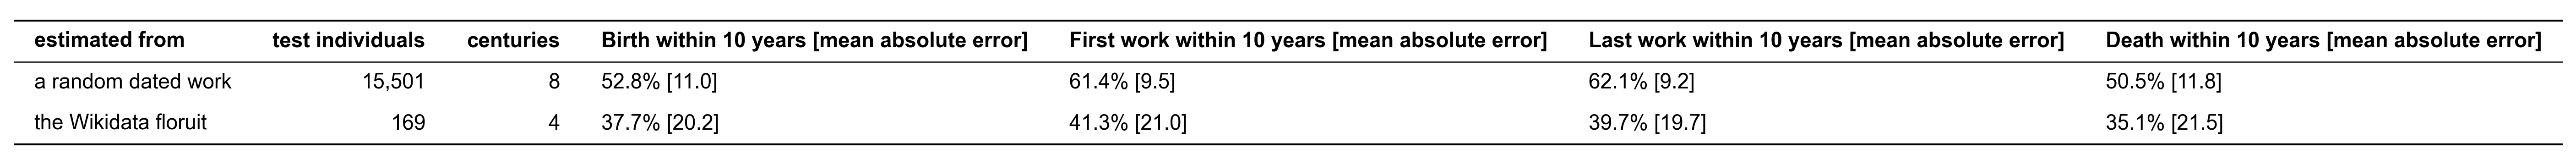

In [18]:
show_table(held_out_scores)

## Estimated dates of 10 random individuals
From the floruit-only and the single-work-year individuals, with the existing date the four dates are estimated from.

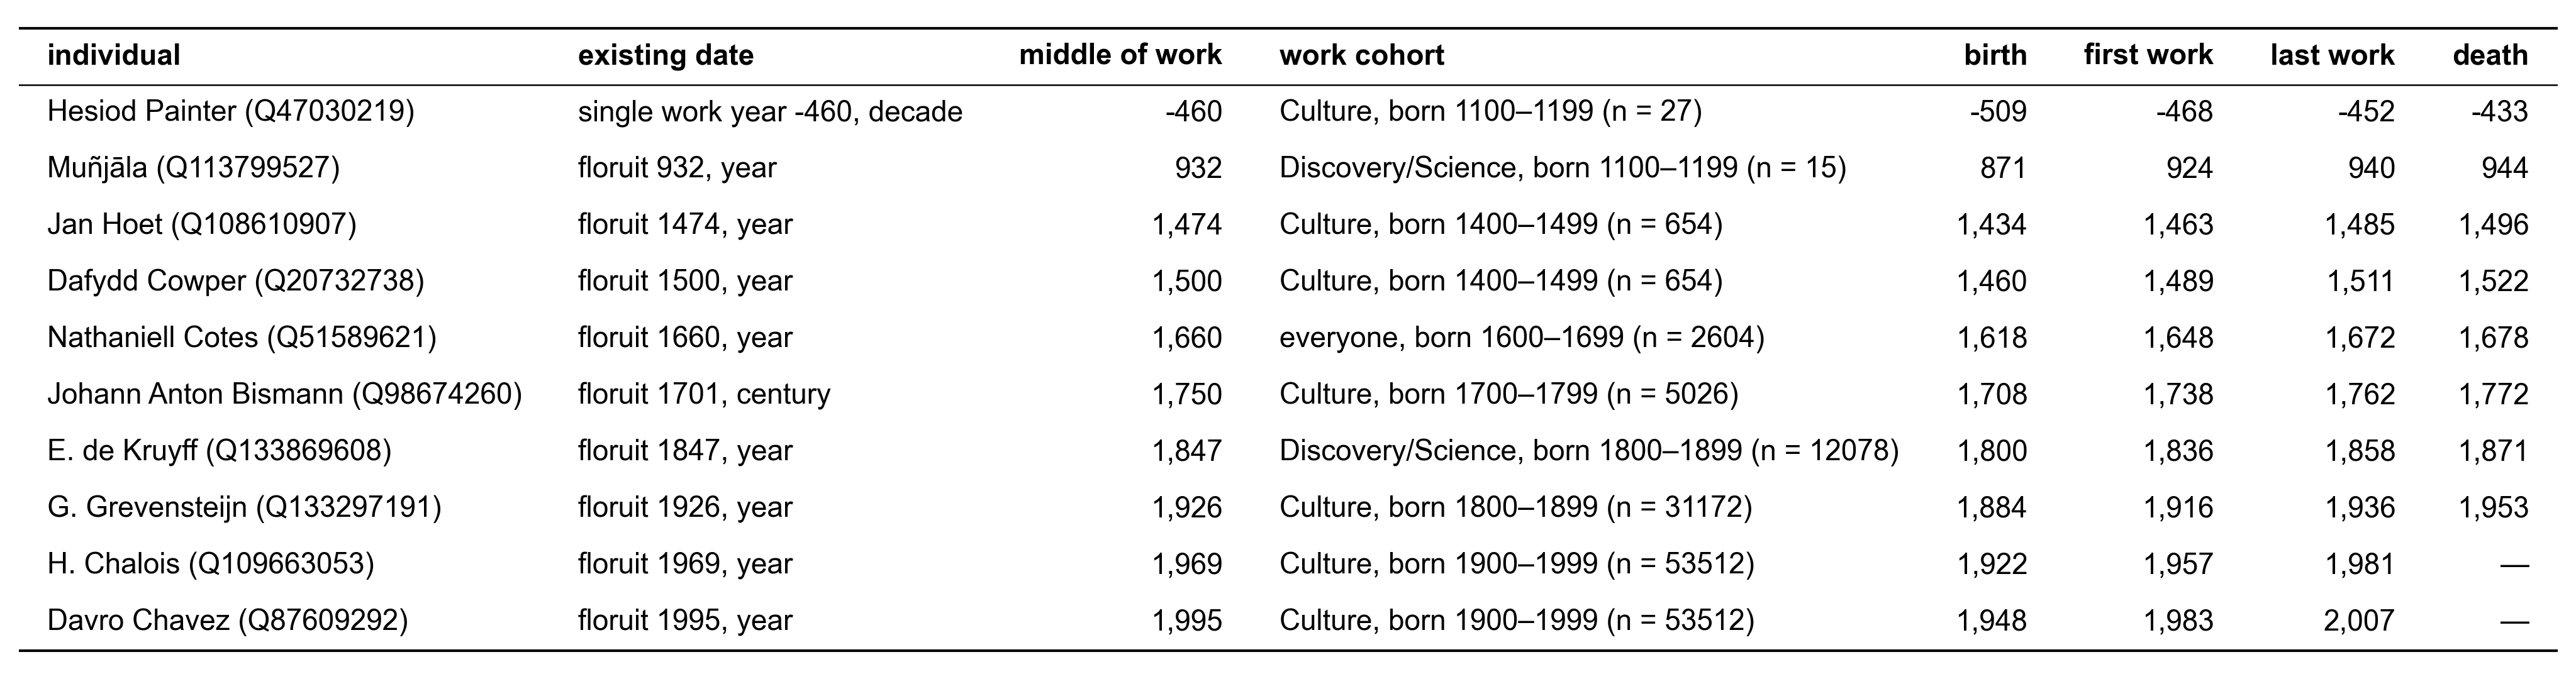

In [19]:
random_examples = estimated.sort('qid').sample(RANDOM_EXAMPLES, seed=SEED).join(people.select('qid', 'name'), on='qid').sort('anchor_year')
show_table(dates_table(random_examples))